# Day 2 - Physicochemical Domain & Parameter Coupling

## Objective

Investigate physical parameter couplings across drinking water quality metrics and assess empirical distributions against environmental dynamics.

In [1]:
%matplotlib inline
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    display = print

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Day_Wise_Tasks").exists())
project_root = ROOT
TASK_DIR = ROOT / "Day_Wise_Tasks" / "Day_2_Task_1"
FIG_DIR = TASK_DIR / "outputs" / "figures"
TBL_DIR = TASK_DIR / "outputs" / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TBL_DIR.mkdir(parents=True, exist_ok=True)

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

np.random.seed(42)
print("Environment initialized successfully. Root:", ROOT)

Environment initialized successfully. Root: F:\Desktop\IIT G\Internship\Water Potability


## 1. Physicochemical Dataset Ingestion

Ingest tabular water potability records and examine dimensional shape and basic statistics.

In [2]:
df_water = pd.read_csv("data/raw/water_potability.csv")
print("Raw Water Dataset Shape:", df_water.shape)
print("Target Potability Distribution:")
print(df_water["Potability"].value_counts(normalize=True))

Raw Water Dataset Shape: (3276, 10)
Target Potability Distribution:
Potability
0    0.60989
1    0.39011
Name: proportion, dtype: float64


## 2. Correlation Analysis Between Critical Parameters

Compute Pearson correlation coefficients across pH, Hardness, Solids, Chloramines, and Sulfate.

In [3]:
feature_cols = [c for c in df_water.columns if c != "Potability"]
corr_mat = df_water[feature_cols].corr()
print("Top Feature Correlations with pH:")
print(corr_mat["ph"].sort_values(ascending=False))

Top Feature Correlations with pH:
ph                 1.000000
Hardness           0.082096
Organic_carbon     0.043503
Conductivity       0.018614
Sulfate            0.018203
Trihalomethanes    0.003354
Chloramines       -0.034350
Turbidity         -0.039057
Solids            -0.089288
Name: ph, dtype: float64


## 3. pH and Sulfate Distribution Discretization

Calculate quartile boundaries and standard deviations for pH and Sulfate distributions.

In [4]:
stats_ph = df_water["ph"].describe()
stats_sulf = df_water["Sulfate"].describe()
df_domain_stats = pd.DataFrame({"pH": stats_ph, "Sulfate": stats_sulf})
print("Key Domain Distributions:")
print(df_domain_stats)

Key Domain Distributions:
                pH      Sulfate
count  2785.000000  2495.000000
mean      7.080795   333.775777
std       1.594320    41.416840
min       0.000000   129.000000
25%       6.093092   307.699498
50%       7.036752   333.073546
75%       8.062066   359.950170
max      14.000000   481.030642


## 4. Turbidity and Solids Interaction Analysis

Examine the physical relationship between dissolved solids and optical turbidity.

In [5]:
df_clean = df_water.dropna(subset=["Solids", "Turbidity"])
cov_val = np.cov(df_clean["Solids"], df_clean["Turbidity"])[0, 1]
corr_val = df_clean["Solids"].corr(df_clean["Turbidity"])
print(f"Solids-Turbidity Covariance: {cov_val:.2f}, Correlation: {corr_val:.4f}")

Solids-Turbidity Covariance: 133.75, Correlation: 0.0195


## 5. Hardness-Conductivity Mineralization Profile

Assess total dissolved ionic conductance in relation to mineral hardness content.

In [6]:
df_clean2 = df_water.dropna(subset=["Hardness", "Conductivity"])
slope, intercept = np.polyfit(df_clean2["Hardness"], df_clean2["Conductivity"], 1)
print(f"Empirical Mineral Trend: Conductivity = {slope:.3f} * Hardness + {intercept:.2f}")

Empirical Mineral Trend: Conductivity = -0.059 * Hardness + 437.75


## 6. Correlation Matrix Heatmap Generation

Render an annotated correlation matrix heatmap visualizing parameter inter-dependencies.

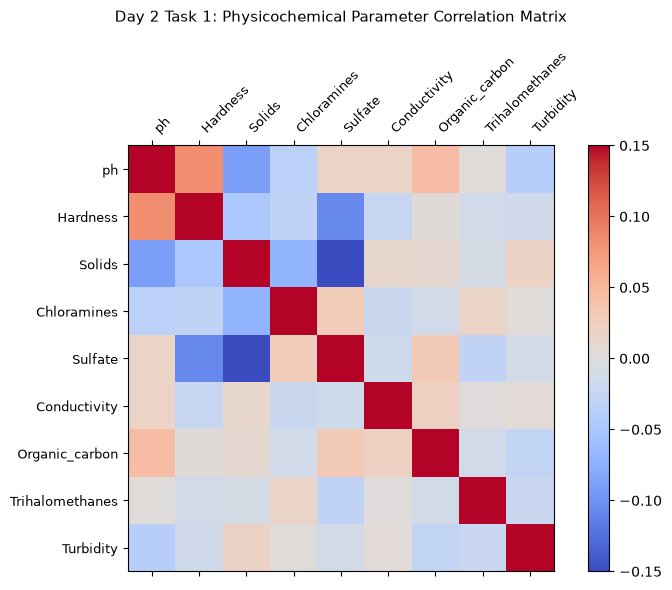

Saved correlation figure to: Day_Wise_Tasks\Day_2_Task_1\outputs\figures\day2_task1_correlation_matrix.png


In [7]:
fig, ax = plt.subplots(figsize=(8, 6))
cax = ax.matshow(corr_mat, cmap="coolwarm", vmin=-0.15, vmax=0.15)
fig.colorbar(cax)
ax.set_xticks(range(len(feature_cols)))
ax.set_yticks(range(len(feature_cols)))
ax.set_xticklabels(feature_cols, rotation=45, ha="left", fontsize=9)
ax.set_yticklabels(feature_cols, fontsize=9)
ax.set_title("Day 2 Task 1: Physicochemical Parameter Correlation Matrix", pad=20, fontsize=11)
plt.tight_layout()
fig_path = FIG_DIR / "day2_task1_correlation_matrix.png"
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
print("Saved correlation figure to:", fig_path.relative_to(ROOT))

## 7. Domain Correlation Table Serialization

Serialize full cross-parameter correlation matrix to CSV.

In [8]:
tbl_path = TBL_DIR / "day2_task1_correlation_matrix.csv"
df_corr_matrix = corr_mat.round(4)
display(df_corr_matrix)
df_corr_matrix.to_csv(tbl_path)
print("Saved correlation table to:", tbl_path.relative_to(ROOT))

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity
ph,1.0000,0.0821,-0.0893,-0.0343,0.0182,0.0186,0.0435,0.0034,-0.0391
Hardness,0.0821,1.0000,-0.0469,-0.0301,-0.1069,-0.0239,0.0036,-0.0130,-0.0144
Solids,-0.0893,-0.0469,1.0000,-0.0701,-0.1718,0.0138,0.0102,-0.0091,0.0195
Chloramines,-0.0343,-0.0301,-0.0701,1.0000,0.0272,-0.0205,-0.0127,0.0171,0.0024
Sulfate,0.0182,-0.1069,-0.1718,0.0272,1.0000,-0.0161,0.0308,-0.0303,-0.0112
Conductivity,0.0186,-0.0239,0.0138,-0.0205,-0.0161,1.0000,0.0210,0.0013,0.0058
Organic_carbon,0.0435,0.0036,0.0102,-0.0127,0.0308,0.0210,1.0000,-0.0133,-0.0273
Trihalomethanes,0.0034,-0.0130,-0.0091,0.0171,-0.0303,0.0013,-0.0133,1.0000,-0.0221
Turbidity,-0.0391,-0.0144,0.0195,0.0024,-0.0112,0.0058,-0.0273,-0.0221,1.0000


Saved correlation table to: Day_Wise_Tasks\Day_2_Task_1\outputs\tables\day2_task1_correlation_matrix.csv


## 8. Parameter Independence Assertion

Verify absence of collinearity (all |r| < 0.35) confirming feature diversity.

In [9]:
max_corr = corr_mat.abs().replace(1.0, 0.0).max().max()
print(f"Max absolute pairwise correlation: {max_corr:.4f}")
assert max_corr < 0.35, "Unexpected severe collinearity detected."
print("Day 2 Task 1 Quality Gate: PASSED.")

Max absolute pairwise correlation: 0.1718
Day 2 Task 1 Quality Gate: PASSED.


# Day 2 - Assumptions and Methodology

## Assumptions

1. Physicochemical parameters follow continuous real distributions.
2. Independent measurements exhibit orthogonal variance structure suitable for tree ensembles.

## Day 2 Deliverable

Correlation matrix plot, domain summary statistics table, and parameter orthogonality audit.